In [1]:
import os, time, copy, random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support
)

# Фиксируем сиды
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| Torch:", torch.__version__)

Device: cpu | Torch: 2.11.0+cpu


## 1. Загрузка датасета

In [2]:
import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [3]:
# Проверим структуру папок
for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    if level < 2:
        indent = "  " * level
        if level < 1:
            for d in dirs:
                print(f"{indent}  {d}/")

  Training/
  Testing/


## 2. Загрузка изображений в память

In [4]:
IMG_SIZE = 128
TRAIN_DIR = os.path.join(path, "Training")
TEST_DIR  = os.path.join(path, "Testing")

classes = sorted(os.listdir(TRAIN_DIR))
print("Классы:", classes)

def load_folder(root, per_class=None):
    images, labels = [], []
    for cls in classes:
        cls_path = os.path.join(root, cls)
        if not os.path.isdir(cls_path):
            continue
        files = sorted(os.listdir(cls_path))
        if per_class is not None:
            files = files[:per_class]
        for name in files:
            try:
                img = Image.open(os.path.join(cls_path, name)).convert("RGB")
                img = img.resize((IMG_SIZE, IMG_SIZE))
            except Exception as e:
                print("skip", name, e); continue
            images.append(np.array(img))
            labels.append(cls)
    return np.array(images, dtype=np.uint8), np.array(labels)

# Возьмём ограниченное число изображений для быстрого обучения
X_train_all, y_train_all = load_folder(TRAIN_DIR, per_class=500)
X_test,      y_test      = load_folder(TEST_DIR,  per_class=100)

print("Train pool:", X_train_all.shape, "Test:", X_test.shape)

Классы: ['glioma', 'meningioma', 'notumor', 'pituitary']
Train pool: (2000, 128, 128, 3) Test: (400, 128, 128, 3)


## 3. EDA: примеры и баланс классов

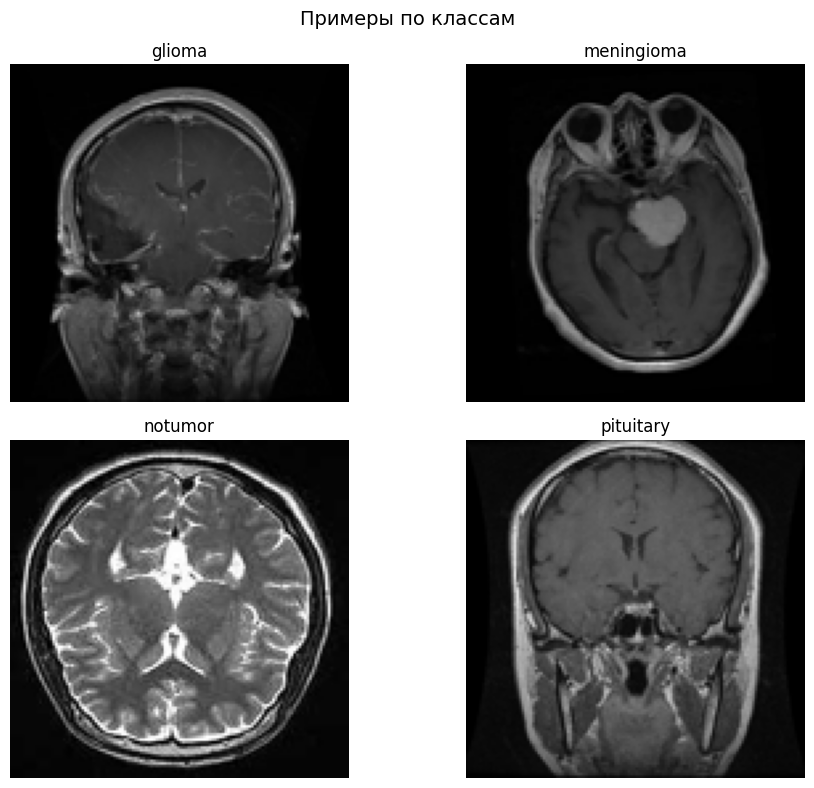

In [5]:
# Примеры изображений по одному на класс
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, cls in zip(axes.ravel(), classes):
    idx = np.where(y_train_all == cls)[0][0]
    ax.imshow(X_train_all[idx])
    ax.set_title(cls)
    ax.axis("off")
plt.suptitle("Примеры по классам", fontsize=14)
plt.tight_layout(); plt.show()

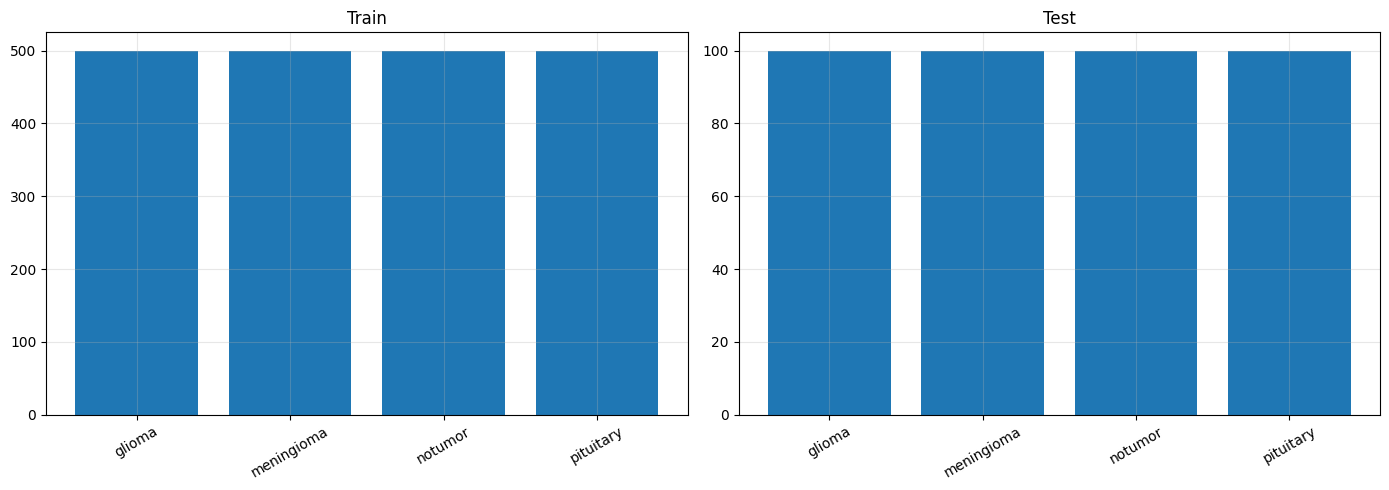

In [6]:
# Баланс классов
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (y_, ttl) in zip(axes, [(y_train_all, "Train"), (y_test, "Test")]):
    u, c = np.unique(y_, return_counts=True)
    ax.bar(u, c); ax.set_title(ttl); ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Train / Val split и Dataset

In [7]:
le = LabelEncoder()
le.fit(classes)
class_names = list(le.classes_)
print("Классы:", class_names)

y_train_all_enc = le.transform(y_train_all)
y_test_enc      = le.transform(y_test)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all_enc,
    test_size=0.2, random_state=SEED, stratify=y_train_all_enc
)
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

Классы: [np.str_('glioma'), np.str_('meningioma'), np.str_('notumor'), np.str_('pituitary')]
Train: 1600, Val: 400, Test: 400


In [8]:
# Нормализация по train
X_train_f = X_train.astype(np.float32) / 255.0
mean = X_train_f.mean(axis=(0, 1, 2)).astype(np.float32)
std  = X_train_f.std(axis=(0, 1, 2)).astype(np.float32)
print("mean:", mean, "std:", std)

train_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

eval_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

class ImageDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label

BATCH_SIZE = 32
train_loader = DataLoader(ImageDataset(X_train, y_train, train_tfms),
                          batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(ImageDataset(X_val,   y_val,   eval_tfms),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(ImageDataset(X_test,  y_test_enc, eval_tfms),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

mean: [0.17893083 0.17894676 0.17898825] std: [0.18844457 0.18844292 0.18848552]


## 5. Собственная CNN

In [9]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        # Блок 1: 3 -> 32
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        # Блок 2: 32 -> 64
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        # Блок 3: 64 -> 128
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        # Блок 4: 128 -> 128
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm2d(128)

        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)

        # 128 -> 64 -> 32 -> 16 -> 8 после 4 MaxPool
        self.fc1 = nn.Linear(128 * (IMG_SIZE // 16) * (IMG_SIZE // 16), 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)

# Проверка
_model = SimpleCNN(num_classes=4).to(device)
with torch.no_grad():
    print(_model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)).shape)

torch.Size([2, 4])


## 6. Обучение и оценка

In [10]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward(); optimizer.step()
        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = criterion(out, yb)
        running_loss += loss.item() * xb.size(0)
        pred = out.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)
        y_true.extend(yb.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())
    return (running_loss / total, correct / total,
            np.array(y_true), np.array(y_pred))

def fit(model, train_loader, val_loader, epochs=15, lr=1e-3,
        weight_decay=0.0, patience=5, title="Model"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )
    history = {"train_loss": [], "val_loss": [],
               "train_acc": [],  "val_acc": [], "time": []}
    best_val_loss, best_state, no_improve = float("inf"), None, 0

    for epoch in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step(va_loss)
        dt = time.time() - t0

        for k, v in zip(["train_loss","val_loss","train_acc","val_acc","time"],
                        [tr_loss, va_loss, tr_acc, va_acc, dt]):
            history[k].append(v)

        print(f"[{title}] Ep {epoch+1:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
              f"lr {optimizer.param_groups[0]['lr']:.2e} | {dt:.1f}s")

        if va_loss < best_val_loss - 1e-4:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping on epoch {epoch+1}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history

In [11]:
cnn_model = SimpleCNN(num_classes=4).to(device)
hist_cnn = fit(cnn_model, train_loader, val_loader,
               epochs=15, lr=1e-3, weight_decay=1e-5,
               patience=4, title="SimpleCNN")

[SimpleCNN] Ep 01/15 | train loss 1.6028 acc 0.4919 | val loss 0.8795 acc 0.6300 | lr 1.00e-03 | 95.2s
[SimpleCNN] Ep 02/15 | train loss 0.8623 acc 0.6281 | val loss 1.0136 acc 0.5450 | lr 1.00e-03 | 98.6s
[SimpleCNN] Ep 03/15 | train loss 0.7873 acc 0.6675 | val loss 0.7054 acc 0.7025 | lr 1.00e-03 | 93.6s
[SimpleCNN] Ep 04/15 | train loss 0.7358 acc 0.6919 | val loss 0.6022 acc 0.8125 | lr 1.00e-03 | 88.4s
[SimpleCNN] Ep 05/15 | train loss 0.6825 acc 0.7075 | val loss 0.7371 acc 0.6550 | lr 1.00e-03 | 90.6s
[SimpleCNN] Ep 06/15 | train loss 0.6489 acc 0.7281 | val loss 0.5136 acc 0.7975 | lr 1.00e-03 | 98.0s
[SimpleCNN] Ep 07/15 | train loss 0.6293 acc 0.7356 | val loss 0.6104 acc 0.6975 | lr 1.00e-03 | 94.6s
[SimpleCNN] Ep 08/15 | train loss 0.5748 acc 0.7488 | val loss 0.4791 acc 0.8025 | lr 1.00e-03 | 99.0s
[SimpleCNN] Ep 09/15 | train loss 0.5261 acc 0.7794 | val loss 0.5609 acc 0.7625 | lr 1.00e-03 | 93.4s
[SimpleCNN] Ep 10/15 | train loss 0.5138 acc 0.7863 | val loss 0.3947 acc

## 7. Transfer Learning: ResNet18

In [ ]:
def build_resnet18(num_classes=4, freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

resnet_model = build_resnet18(num_classes=4, freeze_backbone=False).to(device)
hist_resnet = fit(resnet_model, train_loader, val_loader,
                  epochs=10, lr=3e-4, weight_decay=1e-4,
                  patience=3, title="ResNet18")

## 8. Кривые обучения

In [ ]:
def plot_histories(histories):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    for name, h in histories.items():
        axes[0].plot(h["train_loss"], "--", label=f"{name} train")
        axes[0].plot(h["val_loss"],   "-",  label=f"{name} val")
        axes[1].plot(h["train_acc"],  "--", label=f"{name} train")
        axes[1].plot(h["val_acc"],    "-",  label=f"{name} val")
        axes[2].plot(h["time"],       "-",  label=f"{name}")
    axes[0].set_title("Loss");     axes[0].set_xlabel("Epoch"); axes[0].grid(alpha=0.3)
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].grid(alpha=0.3)
    axes[2].set_title("Time per epoch (s)"); axes[2].set_xlabel("Epoch"); axes[2].grid(alpha=0.3)
    for ax in axes: ax.legend()
    plt.tight_layout(); plt.show()

plot_histories({"SimpleCNN": hist_cnn, "ResNet18": hist_resnet})

## 9. Оценка на тестовой выборке

In [ ]:
def full_report(model, loader, title):
    criterion = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred = evaluate(model, loader, criterion)
    print(f"\n{'='*60}\n{title} — Test Accuracy: {acc:.4f}\n{'='*60}")
    print(classification_report(y_true, y_pred,
                                target_names=class_names, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion Matrix — {title}")
    plt.show()
    return {"acc": acc, "y_true": y_true, "y_pred": y_pred}

res_cnn    = full_report(cnn_model,    test_loader, "SimpleCNN")
res_resnet = full_report(resnet_model, test_loader, "ResNet18")

## 10. Сравнение моделей

In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def summarize(name, hist, res, model):
    p, r, f, _ = precision_recall_fscore_support(
        res["y_true"], res["y_pred"], average="macro", zero_division=0
    )
    return {
        "Model": name,
        "Params": f"{count_params(model):,}",
        "Best val acc": f"{max(hist['val_acc']):.4f}",
        "Test acc":     f"{res['acc']:.4f}",
        "Macro precision": f"{p:.4f}",
        "Macro recall":    f"{r:.4f}",
        "Macro F1":        f"{f:.4f}",
        "Mean epoch time (s)": f"{np.mean(hist['time']):.1f}",
        "Epochs trained": len(hist["time"]),
    }

df_cmp = pd.DataFrame([
    summarize("SimpleCNN", hist_cnn,    res_cnn,    cnn_model),
    summarize("ResNet18",  hist_resnet, res_resnet, resnet_model),
]).set_index("Model")
df_cmp

## 11. Визуализация предсказаний

In [ ]:
@torch.no_grad()
def show_predictions(model, images, labels, n=8, title="Model"):
    model.eval()
    idxs = np.random.choice(len(images), n, replace=False)
    fig, axes = plt.subplots(2, n // 2, figsize=(15, 7))
    for ax, i in zip(axes.ravel(), idxs):
        tensor = eval_tfms(images[i]).unsqueeze(0).to(device)
        prob = torch.softmax(model(tensor), dim=1).cpu().numpy().ravel()
        pred = int(np.argmax(prob))
        ax.imshow(images[i])
        color = "green" if pred == labels[i] else "red"
        ax.set_title(f"true: {class_names[labels[i]]}\n"
                     f"pred: {class_names[pred]} ({prob[pred]:.2f})",
                     color=color)
        ax.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()

show_predictions(cnn_model,    X_test, y_test_enc, n=8, title="SimpleCNN")
show_predictions(resnet_model, X_test, y_test_enc, n=8, title="ResNet18")